In [79]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models


In [80]:
df = pd.read_csv("mnist_train.csv")
df_test = pd.read_csv("mnist_test.csv")

In [81]:
df.head()   #label = 5 ,  and image is 28*28 pixcel , and it is going to 1*1 to 28*28

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [82]:
df_test.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [83]:
df.shape  # you can see 60k images  and we store as pixel

(60000, 785)

In [84]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


Preprocess

In [85]:
X_train = df.drop("label",axis=1).values
y_train = df["label"].values
X_test = df_test.drop("label",axis=1).values
y_test = df_test["label"].values

In [86]:
# I will convert vaulues between 0 and 1  to get better result
X_train = X_train.astype('float32')/255.0    # Divide 255 to get result between 0 and 1
X_test = X_test.astype('float32')/255.0


Now we will do reshape

In [87]:
X_train_img = X_train.reshape(-1,28,28)
X_test_img = X_test.reshape(-1,28,28)     # -1 is for 1st columns and 28 * 28 is for  images

In [88]:
X_train_img  # Now you can see 2d matrix , axtullay we convert acutal values into pixcel

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

There has catagorical data , so we need to convert one hot encoding

In [89]:
y_train_cat = to_categorical(y_train,10)
y_test_cat = to_categorical(y_test,10)

Let's create perceptron model

In [90]:
# In perceptron you know there has one input layer and other is output layer

In [91]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),  # Flatten is for convert arrray format of the 28*28 matrix
    Dense(10,activation='softmax') # Output will be 10 layers as 1 ,2 , 3, ....,10
]) # There has not any hidden layers , as the model is perceptron

In [92]:
perceptron.compile(optimizer='sgd',loss='categorical_crossentropy',metrics=['accuracy'])

Now we will do traing start

In [93]:
history_percp = perceptron.fit(X_train_img,y_train_cat,epochs=5,
batch_size = 32 , validation_data = (X_test_img,y_test_cat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8144 - loss: 0.7774 - val_accuracy: 0.8811 - val_loss: 0.4782
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8806 - loss: 0.4556 - val_accuracy: 0.8946 - val_loss: 0.3987
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8910 - loss: 0.4030 - val_accuracy: 0.9019 - val_loss: 0.3665
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8971 - loss: 0.3764 - val_accuracy: 0.9059 - val_loss: 0.3475
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9010 - loss: 0.3597 - val_accuracy: 0.9095 - val_loss: 0.3354


In [94]:
acc_percp = perceptron.evaluate(X_test_img,y_test_cat,verbose=0)[1]

In [95]:
acc_percp  # See accuracy

0.909500002861023

# Now we will apply ANN

For ANN we need to create hidden Layers


In [96]:
ann = Sequential([          # Sequential use for multiple layers
    Flatten(input_shape=(28,28)), # 785 inputs as you can see in columns shape # Alredy know why Flatten use for ( Convert into array)
    Dense(128,activation='relu'),  # Hidden layer with 128 Layers
    Dense(64,activation='relu'),   #68 hidden neuron
    Dense(10,activation='softmax')  # last layer like output layers , use softmax to predict like 1 , 3,  ...,10
])  # so weight will be so high -- 785*28*64*10

In [97]:
# Use Adam optimizer as we are using ANN , it's best for ANN

MOdel compile

In [98]:
ann.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [99]:
history_ann = ann.fit(X_train_img,y_train_cat,epochs=5,
batch_size = 32 , validation_data = (X_test_img,y_test_cat),verbose=1)  # batch 32 means we want to sent 1st 32 rows or columns and then 32 ....

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9312 - loss: 0.2381 - val_accuracy: 0.9624 - val_loss: 0.1195
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9694 - loss: 0.0986 - val_accuracy: 0.9746 - val_loss: 0.0809
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9781 - loss: 0.0689 - val_accuracy: 0.9742 - val_loss: 0.0789
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9831 - loss: 0.0511 - val_accuracy: 0.9758 - val_loss: 0.0838
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9871 - loss: 0.0413 - val_accuracy: 0.9773 - val_loss: 0.0786


In [100]:
# You can see it has more accuracy than perceptron as useul

In [101]:
acc_ann = ann.evaluate(X_test_img,y_test_cat,verbose=0)[1]  # to see final accuracy

In [102]:
acc_ann

0.9772999882698059

# Now main part for the videos is CNN

In [103]:
#In CNN there has more layers

In [104]:
X_train_cnn = X_train_img.reshape(-1,28,28,1)  # last number  represents the number of colour # if you use any RGB image that time you need to put 3 in last
X_test_cnn = X_test_img.reshape(-1,28,28,1)

In [105]:
cnn = Sequential([
    Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(28,28,1)),  # 1st layer is convolution layer and filter is 3,3  .. Relu for convert values between 0 and 1 .. input shape 28*28 pixcel and 1 is for chanel
    MaxPooling2D(pool_size=(2,2)), # To deal with convolution layer , 2,2 pixcel go and find max
    Conv2D(64,kernel_size=(3,3),activation='relu'), # again concolution layer
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),  #To convert all in an  one D array
    Dense(128,activation='relu'), # Hidden layer
    Dropout(0.5),   # Drop  50% so that we can use all pixcel and model do not overfit
    Dense(10,activation='softmax') # OUtput layer . values will be 10 .  1,2,3,4,....,10
])

Now we will add OPtimizers

In [106]:
# To optimizer we need to compile

In [107]:
cnn.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [108]:
# Train model (Fit)

In [109]:
history_cnn = cnn.fit(X_train_cnn,y_train_cat,epochs=5,
batch_size = 32 , validation_data = (X_test_cnn,y_test_cat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 64s 34ms/step - accuracy: 0.9409 - loss: 0.1977 - val_accuracy: 0.9845 - val_loss: 0.0481
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 60s 32ms/step - accuracy: 0.9780 - loss: 0.0747 - val_accuracy: 0.9888 - val_loss: 0.0313
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 61s 33ms/step - accuracy: 0.9842 - loss: 0.0532 - val_accuracy: 0.9911 - val_loss: 0.0263
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 33ms/step - accuracy: 0.9866 - loss: 0.0432 - val_accuracy: 0.9888 - val_loss: 0.0344
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 60s 32ms/step - accuracy: 0.9884 - loss: 0.0367 - val_accuracy: 0.9908 - val_loss: 0.0266


In [110]:
acc_cnn = cnn.evaluate(X_test_cnn,y_test_cat,verbose=0)[1]  # To see accuracy

In [111]:
acc_cnn

0.9908000230789185

# Done till  CNN

In [112]:
# just visulize

In [119]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

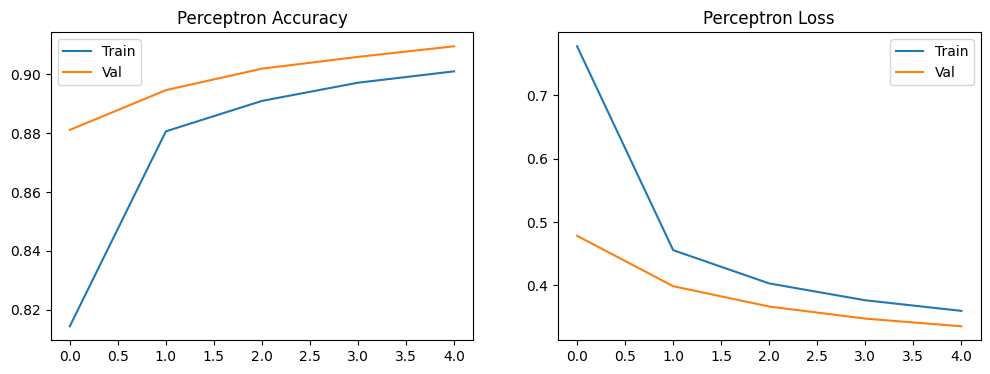

In [120]:
plot_training(history_percp,"Perceptron")

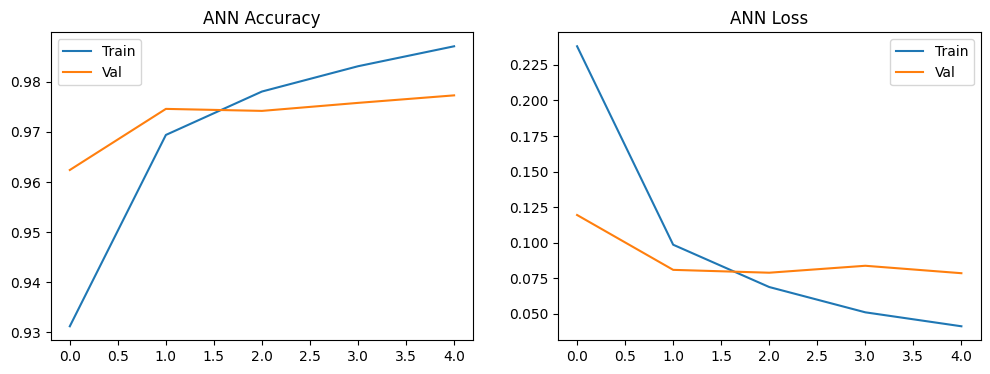

In [121]:
plot_training(history_ann,"ANN")

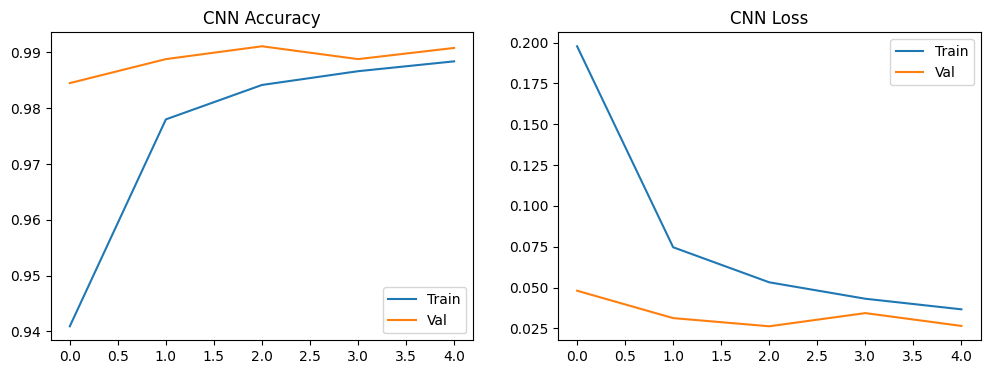

In [122]:
plot_training(history_cnn,"CNN")

### Model Accuracy Comparison
Let's plot a bar chart to visually compare the final test accuracies of the Perceptron, ANN, and CNN models.

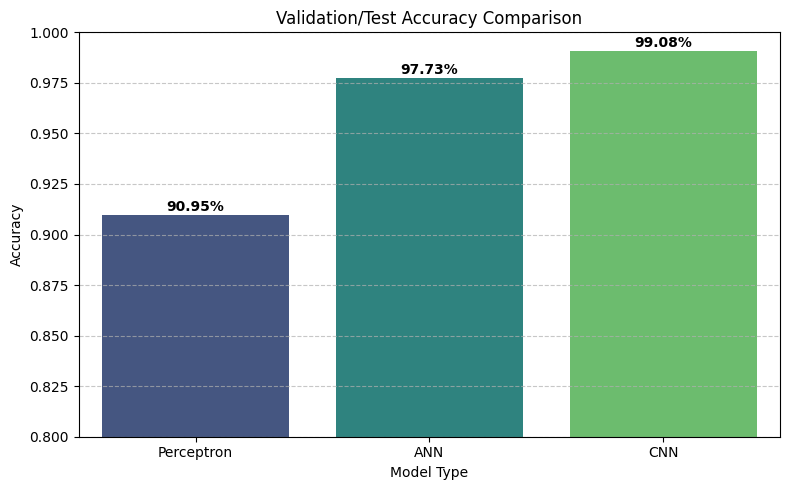

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gather accuracies
models = ['Perceptron', 'ANN', 'CNN']
accuracies = [acc_percp, acc_ann, acc_cnn]

# Create the plot
plt.figure(figsize=(8, 5))
sns.barplot(x=models, y=accuracies, palette='viridis')

# Add details
plt.title('Validation/Test Accuracy Comparison')
plt.xlabel('Model Type')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.0)  # Zoom in to highlight differences

# Display values on top of the bars
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.002, f"{acc*100:.2f}%", ha='center', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Side-by-Side Prediction Comparison
Let's visualize some random digits from our test dataset and compare the actual label with the predictions generated by our Perceptron, ANN, and CNN models.

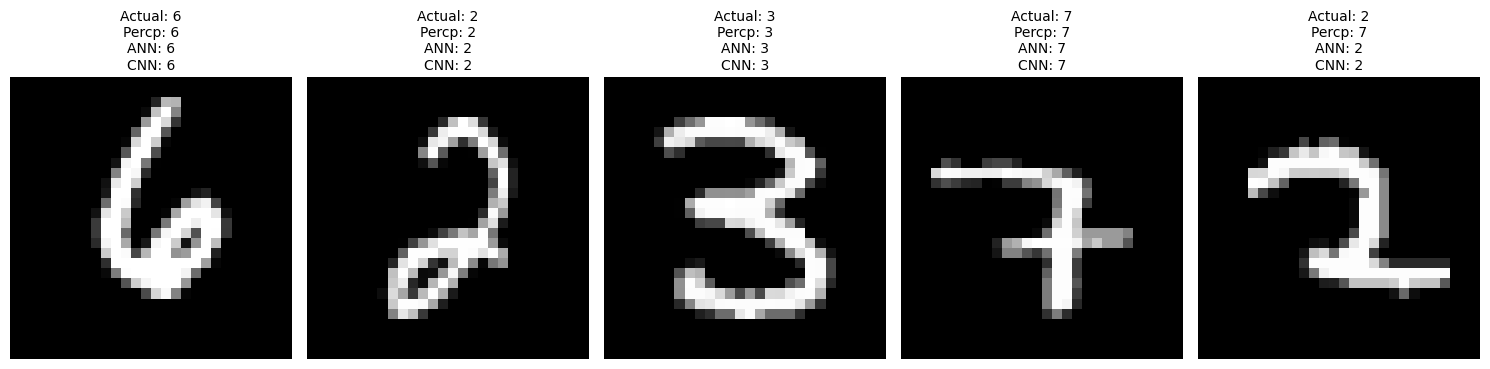

In [124]:
import numpy as np
import matplotlib.pyplot as plt

# Get model predictions on the test set
pred_percp_probs = perceptron.predict(X_test_img, verbose=0)
pred_ann_probs = ann.predict(X_test_img, verbose=0)
pred_cnn_probs = cnn.predict(X_test_cnn, verbose=0)

# Convert probabilities to class labels
pred_percp = np.argmax(pred_percp_probs, axis=1)
pred_ann = np.argmax(pred_ann_probs, axis=1)
pred_cnn = np.argmax(pred_cnn_probs, axis=1)

# Select 5 random indices from the test set to display
np.random.seed(42)  # Set seed for reproducible samples
sample_indices = np.random.choice(len(X_test_img), size=5, replace=False)

# Set up the plot grid
fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for i, idx in enumerate(sample_indices):
    # Display the digit image
    axes[i].imshow(X_test_img[idx], cmap='gray')
    axes[i].axis('off')

    # Get true label and predictions
    true_label = y_test[idx]
    p_val = pred_percp[idx]
    a_val = pred_ann[idx]
    c_val = pred_cnn[idx]

    # Color green if correct, red if incorrect
    p_color = 'green' if p_val == true_label else 'red'
    a_color = 'green' if a_val == true_label else 'red'
    c_color = 'green' if c_val == true_label else 'red'

    # Title content with prediction comparisons
    title_str = f"Actual: {true_label}\n"
    title_str += f"Percp: {p_val}\n"
    title_str += f"ANN: {a_val}\n"
    title_str += f"CNN: {c_val}"

    axes[i].set_title(title_str, fontsize=10, loc='center')

plt.tight_layout()
plt.show()

### Confusion Matrix Heatmaps
Let's plot confusion matrices for all three models side-by-side to visualize exactly which digits are frequently misclassified (where the "hits" and "misses" are concentrated).

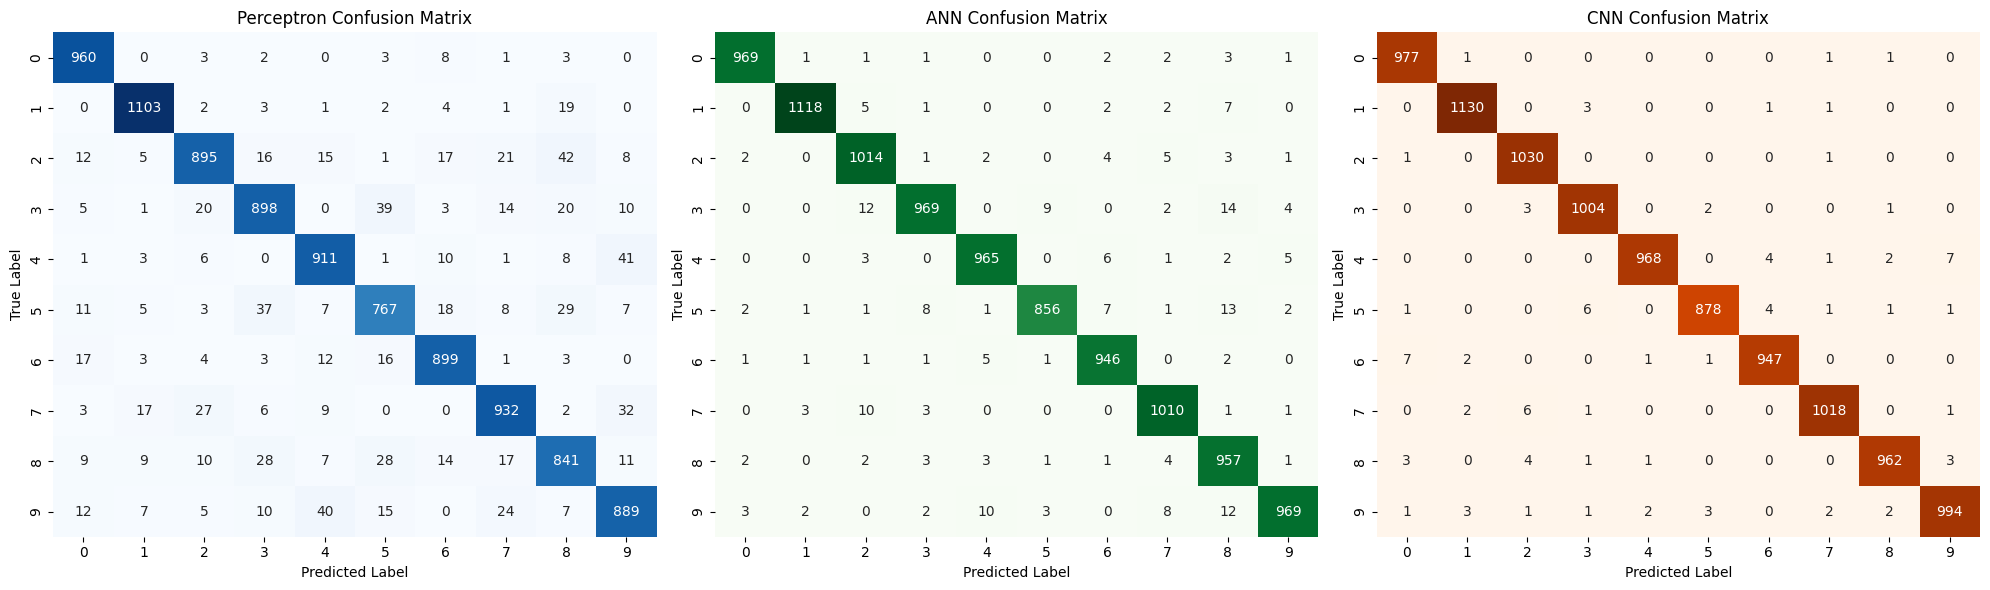

In [125]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrices
cm_percp = confusion_matrix(y_test, pred_percp)
cm_ann = confusion_matrix(y_test, pred_ann)
cm_cnn = confusion_matrix(y_test, pred_cnn)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot Perceptron Confusion Matrix
sns.heatmap(cm_percp, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Perceptron Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot ANN Confusion Matrix
sns.heatmap(cm_ann, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('ANN Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# Plot CNN Confusion Matrix
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Oranges', ax=axes[2], cbar=False)
axes[2].set_title('CNN Confusion Matrix')
axes[2].set_xlabel('Predicted Label')
axes[2].set_ylabel('True Label')

plt.tight_layout()
plt.show()